# Módulo 7 — TDS, clasificación y resultados

| | |
|---|---|
| **Responde** | Resultados/diagnóstico · metodología 7 y 9 · hipótesis 2 |
| **Código** | `clasificacion_resultados.py` (en esta misma carpeta) |
| **Recibe** | la tabla de características, una fila por imagen |
| **Devuelve** | métricas, figuras y tablas finales |
| **Responsable** | Lucas D'Elia |

## Qué hace este módulo

M7 junta lo que miden los módulos anteriores y decide si cada lesión es sospechosa. Calcula el TDS de la regla, $1{,}3\,A + 0{,}1\,B + 0{,}5\,C + 0{,}5\,D$, y un **TDS extendido**, que le suma los dos contrastes de zonas elegidos en M6, llevados a la misma escala con la media y el desvío de entrenamiento. Una lesión es sospechosa si su puntaje supera un umbral, que puede ser el clínico (4,75) o el que mejor separa en entrenamiento (índice de Youden).

También es el módulo que evalúa el algoritmo en las **60 imágenes de prueba**, que no se usaron para elegir nada. El cuaderno sigue el recorrido de una imagen. Primero mira si la lesión se encuentra bien (sección 2) y si los criterios coinciden con el dermatólogo (sección 3). Después evalúa la clasificación con el TDS (sección 4) y si los términos de zonas la mejoran (sección 5), que son las dos partes de la hipótesis 2. Al final responde la hipótesis 1, sobre la remoción de pelos (sección 6).

Las funciones de cálculo (TDS, umbrales, AUC, κ, intervalos) están en `clasificacion_resultados.py`.

In [1]:
# Permite usar el código de las otras carpetas del repo
import sys
sys.path.insert(0, "../..")

# Recarga los cambios que hagas en los archivos .py sin reiniciar el cuaderno
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
from scipy import stats

from modulos.herramientas import graficos, procesamiento_completo as pc
from modulos.m0_carga_de_datos import carga_de_datos
from modulos.m1_mejoramiento import mejoramiento
from modulos.m3_segmentacion import segmentacion
from modulos.m5_textura_criterio_d import textura_criterio_d
from modulos.m7_clasificacion_resultados import clasificacion_resultados as m7

graficos.aplicar_estilo()

## 1. Datos

`python main.py` procesa las 200 imágenes con todos los módulos y guarda una fila por imagen en `resultados/caracteristicas.csv`, con A, B y C de M4, los atributos y las medidas de estructuras de M5, los contrastes de zonas de M6, el Dice de la segmentación y lo que anotó el dermatólogo. La tabla no guarda D, sino la medida de cada una de las cinco estructuras, porque para pasar de las medidas a D hacen falta umbrales, y esos umbrales se eligen mirando todas las imágenes de entrenamiento juntas. Por eso, al leer la tabla, `completar_d` elige el umbral de cada estructura con las filas de entrenamiento, decide con esos umbrales qué estructuras tiene cada imagen y cuenta cuántas son. Ese conteo es el D estimado.

Hacen falta además dos cosas que `main.py` no guarda. Para la hipótesis 1 hay que segmentar cada imagen con los tres métodos de pelos (sin quitarlos, con un filtro de mediana y con el cierre de M1), y para la sección 5 hace falta el brillo de la lesión. La celda siguiente las calcula y las agrega a la tabla.

In [2]:
def medidas_extra(caso):
    """Segmenta la imagen con cada método de pelos y mide el brillo de la lesión.

    Entra: caso   Caso de M0
    Sale : dict con el Dice de cada método de pelos, la fracción de la imagen marcada como pelo
           y la mediana del brillo V dentro de la lesión (con el método elegido, el cierre)
    """
    salida = {"nombre": caso.nombre}
    for metodo in mejoramiento.METODOS_PELOS:
        mejorada, valida, pelos = mejoramiento.mejorar(caso.imagen, metodo)
        mascara = segmentacion.segmentar(mejorada, valida)
        salida[f"dice_{metodo}"] = segmentacion.dice(mascara, caso.mascara_ref)
    # el último de METODOS_PELOS es "cierre", el que usa el algoritmo
    salida["fraccion_pelos"] = pelos.mean()
    salida["V_lesion"] = np.median(mejoramiento.a_hsv(mejorada)[..., 2][mascara])
    return salida

tabla = pc.completar_d(pd.read_csv("../../resultados/caracteristicas.csv", dtype={"nombre": str}))
extras = pd.DataFrame([medidas_extra(carga_de_datos.cargar_caso(n)) for n in carga_de_datos.nombres("todos")])
tabla = tabla.merge(extras, on="nombre")
entrenamiento, prueba = tabla[tabla.conjunto == "entrenamiento"], tabla[tabla.conjunto == "prueba"]
real_e, real_p = entrenamiento.sospechosa.to_numpy(bool), prueba.sospechosa.to_numpy(bool)
print(len(entrenamiento), "imágenes de entrenamiento y", len(prueba), "de prueba;", int(real_p.sum()), "sospechosas en prueba")

140 imágenes de entrenamiento y 60 de prueba; 36 sospechosas en prueba


## 2. Segmentación

Todo lo demás se mide sobre la máscara de M3, así que primero hay que ver si encuentra bien la lesión. El Dice compara la máscara con la dibujada a mano en PH2, y vale 1 si coinciden y 0 si no comparten ningún píxel. Una imagen falla si su Dice es menor a 0,7.

In [3]:
# Dice medio, mediana, peor caso y fallas en cada conjunto
resumen = pd.DataFrame([{"conjunto": n, "imágenes": len(t), "Dice medio": t.dice.mean(), "mediana": t.dice.median(),
                         "peor": t.dice.min(), "fallas": (t.dice < 0.7).sum()}
                        for n, t in (("entrenamiento", entrenamiento), ("prueba", prueba))])
graficos.guardar_tabla(resumen, "m7_dice", decimales=3)
resumen

,conjunto,imágenes,Dice medio,mediana,peor,fallas
0,entrenamiento,140,0.908343,0.931045,0.500659,2
1,prueba,60,0.916306,0.945954,0.299714,2


La segmentación encuentra bien la lesión, con un Dice medio de 0,916 y una mediana de 0,946 en prueba, parecidos a los de entrenamiento (0,908 y 0,931). Que sean parecidos indica que el método no quedó ajustado de más a las imágenes de entrenamiento. Falla en 2 imágenes de cada conjunto, y las 4 son melanomas con azul grisáceo, que en el canal azul se ven casi como la piel (ver el cuaderno de M3).

## 3. ¿Coinciden los criterios con el dermatólogo?

El TDS depende de que A, C y D se parezcan a lo que mide el dermatólogo. Para A y C se usa el **κ de Cohen**, que mide cuánto coinciden dos evaluaciones descontando lo que coincidirían por azar. Vale 1 si el acuerdo es perfecto y 0 si es el esperable por azar, y entre 0,21 y 0,40 se considera aceptable y entre 0,41 y 0,60, moderado. B no se puede comparar, porque PH2 no lo anota.

Para D, además del valor total, se mira cada estructura por separado. Ahí se usa el **AUC**, que es la probabilidad de que una imagen con la estructura tenga una medida más alta que una sin ella. Vale 0,5 si la medida no distingue nada y 1 si separa perfectamente. La sensibilidad es la fracción de imágenes con la estructura que el detector encuentra, y la especificidad, la fracción de imágenes sin ella que deja sin marcar.

In [4]:
# Acuerdo de A, C y D con el dermatólogo en prueba
acuerdo = pd.DataFrame([{"criterio": k, "acierto exacto": (prueba[k] == prueba[f"{k}_derm"]).mean(),
                         "kappa": m7.kappa_cohen(prueba[k], prueba[f"{k}_derm"])} for k in ("A", "C", "D")])
print(acuerdo.round(3).to_string(index=False))
print("D: decir siempre la mediana de entrenamiento acierta en", round(float((prueba.D_derm == entrenamiento.D_derm.median()).mean()), 3))

# Cada detector de estructura, con el umbral elegido en entrenamiento
filas = []
for e in textura_criterio_d.ESTRUCTURAS:
    real = prueba[f"derm_{e}"].to_numpy(bool)
    piso = entrenamiento[f"estr_{e}"].min()
    filas.append({"estructura": e, "imágenes con la estructura": int(real.sum()),
                  "AUC entrenamiento": m7.auc(entrenamiento[f"estr_{e}"].fillna(piso), entrenamiento[f"derm_{e}"].to_numpy(bool)),
                  "AUC prueba": m7.auc(prueba[f"estr_{e}"].fillna(piso), real),
                  **{k: v for k, v in m7.metricas(prueba[f"detectada_{e}"].to_numpy(bool), real).items() if k in ("sensibilidad", "especificidad")}})
estructuras_prueba = pd.DataFrame(filas)
graficos.guardar_tabla(estructuras_prueba, "m7_estructuras_prueba", decimales=2)
estructuras_prueba.round(3)

criterio  acierto exacto  kappa
       A           0.667  0.384
       C           0.450  0.236
       D           0.267  0.074
D: decir siempre la mediana de entrenamiento acierta en 0.5


,estructura,imágenes con la estructura,AUC entrenamiento,AUC prueba,sensibilidad,especificidad
0,red_pigmento,34,0.664,0.607,0.676,0.462
1,puntos_globulos,35,0.603,0.627,0.771,0.440
2,estrias,12,0.785,0.665,0.833,0.562
3,regresion,6,0.787,0.790,0.833,0.759
4,velo,12,0.945,0.934,0.917,0.750


**Asimetría.** Coincide con el dermatólogo en el 67 % de las imágenes, con κ = 0,38, un acuerdo aceptable. La principal diferencia es que el dermatólogo también mira si los colores y las estructuras se reparten de forma simétrica, y nosotros sólo miramos la forma del contorno (ver M4).

**Color.** Coincide exactamente en el 45 % de las imágenes, con κ = 0,24. El marrón claro aparece de más y el blanco casi nunca se encuentra (ver M4).

**Criterio D.** El valor exacto se acierta en el 27 % de las imágenes, menos que decir siempre la mediana (50 %), con κ = 0,07. Mirando estructura por estructura, el velo (AUC 0,93) y la regresión (0,79) se detectan bien y casi igual que en entrenamiento. Las estrías bajan de 0,79 a 0,67, aunque hay sólo 12 imágenes de prueba con estrías. La red atípica (0,61) y los puntos y glóbulos (0,63) se detectan peor, y además con especificidad baja (0,46 y 0,44), o sea que se marcan en muchas imágenes que no las tienen. Por eso el D estimado tiende a pasarse. Aun así, como se ve en la sección 5, ordena bien las lesiones, que es lo que le importa al TDS.

## 4. Clasificación con el TDS (hipótesis 2, primera parte)

La primera parte de la hipótesis 2 dice que el TDS automático separa las lesiones sospechosas (nevos atípicos y melanomas) de los nevos comunes. Se compara con dos umbrales.

- El **umbral clínico** (4,75), el de la regla original. Como nuestro D se mide distinto que el original, no es seguro que funcione igual.
- El **umbral de Youden**, elegido en entrenamiento. Es el que maximiza J = sensibilidad + especificidad − 1, o sea, el que mejor equilibra no perder lesiones sospechosas y no marcar de más.

Con 60 imágenes un AUC puede variar bastante por azar, así que va con su **intervalo de confianza del 95 %**. Se calcula sorteando 2000 veces muestras con reposición de las mismas imágenes, respetando cuántas sospechosas y comunes hay, y tomando el rango donde cae el 95 % central de los AUC. Si el intervalo no incluye al 0,5, el TDS separa mejor que el azar.

`m7.generar` calcula la tabla y guarda las curvas ROC y la distribución del TDS por grupo, que muestran sensibilidad y especificidad para todos los umbrales posibles.

  AUC extendido - TDS en prueba: 0.019 (IC 95 %: -0.057 a 0.094)


,clasificador,umbral,sensibilidad,especificidad,AUC,AUC inf.,AUC sup.
0,"TDS, umbral clínico",4.750,0.389,0.958,0.775,0.647,0.886
1,"TDS, umbral de Youden",3.250,0.694,0.875,0.775,0.647,0.886
2,"TDS extendido, umbral de Youden",3.488,0.722,0.750,0.794,0.668,0.902


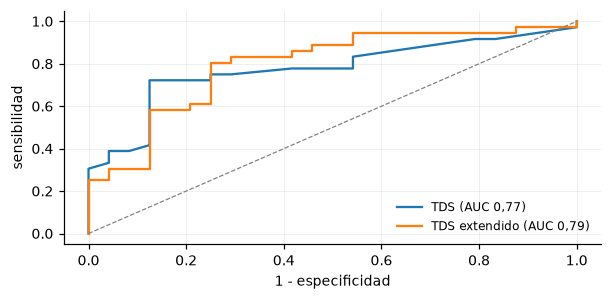

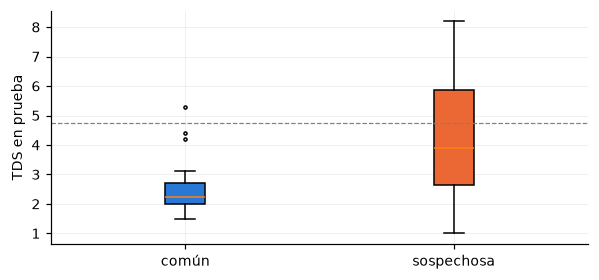

In [5]:
# Los tres clasificadores en prueba, con los umbrales elegidos en entrenamiento
m7.generar(tabla)
pd.read_csv("../../informe/tablas/m7_clasificacion.csv").round(3)

El TDS automático separa las lesiones sospechosas de los nevos comunes con un AUC de 0,77, y su intervalo (0,65 a 0,89) no incluye al 0,5, así que **la primera parte de la hipótesis 2 se confirma**.

El umbral clínico de 4,75 resulta muy conservador con nuestro TDS. Detecta sólo el 39 % de las sospechosas, aunque casi no se equivoca con los nevos comunes (especificidad 0,96). El umbral de Youden, 3,25, equilibra mejor, con sensibilidad 0,69 y especificidad 0,88. Que el mejor umbral quede más abajo es esperable, porque nuestro D adaptado parte de 0 y no de 1, y el borde automático suele dar valores bajos (en M4, su mediana va de 0 en los nevos comunes a 1,5 en los melanomas).

## 5. ¿Suman las zonas? (hipótesis 2, segunda parte)

La segunda parte de la hipótesis 2 dice que agregarle al TDS los términos de zonas mejora la separación. Se compara el AUC del TDS extendido con el del TDS sobre las mismas imágenes, y la mejora es significativa si el intervalo de esa diferencia no incluye al 0.

En M6 se vio que el primer término, la saturación periferia − centro, sigue de cerca al brillo de la lesión, que también separa por sí solo. Por eso la tabla muestra también cuánto separa cada término solo, y el brillo. Para medir cuánto se parecen dos medidas se usa la **correlación de Spearman** (ρ), que vale 1 si ordenan igual las imágenes, 0 si no tienen relación y −1 si las ordenan al revés.

In [6]:
# Diferencia de AUC entre el TDS extendido y el TDS, sobre las mismas imágenes de prueba
tds_p = m7.tds(prueba.A, prueba.B, prueba.C, prueba.D).to_numpy(float)
extendido_p = m7.tds_extendido(prueba, m7.TERMINOS_EXTRA, entrenamiento)
print("AUC extendido - AUC TDS en prueba: %.3f (IC 95 %%: %.3f a %.3f)" % m7.diferencia_auc(extendido_p, tds_p, real_p))

# Cuánto separa cada término solo, y el brillo de la lesión
medidas = {"D estimado": "D", "Periferia - centro, S": "zona_periferia_vs_centro_S",
           "Piel - lesión, S": "zona_interfase_S", "Oscuridad de la lesión (-V)": "V_lesion"}
filas = []
for nombre, columna in medidas.items():
    signo = -1 if columna == "V_lesion" else 1
    valor, inferior, superior = m7.intervalo_auc(signo * prueba[columna].to_numpy(float), real_p)
    filas.append({"medida": nombre, "AUC entrenamiento": m7.auc(signo * entrenamiento[columna].to_numpy(float), real_e),
                  "AUC prueba": valor, "IC 95 % inf.": inferior, "IC 95 % sup.": superior})
auc_prueba = pd.DataFrame(filas)
graficos.guardar_tabla(auc_prueba, "m7_auc_prueba", decimales=2)
print("rho entre la saturación periferia - centro y el brillo de la lesión, en prueba:",
      round(stats.spearmanr(prueba.zona_periferia_vs_centro_S, prueba.V_lesion).statistic, 2))
auc_prueba.round(3)

AUC extendido - AUC TDS en prueba: 0.019 (IC 95 %: -0.057 a 0.094)


rho entre la saturación periferia - centro y el brillo de la lesión, en prueba: -0.67


,medida,AUC entrenamiento,AUC prueba,IC 95 % inf.,IC 95 % sup.
0,D estimado,0.762,0.667,0.538,0.797
1,"Periferia - centro, S",0.764,0.712,0.578,0.837
2,"Piel - lesión, S",0.685,0.602,0.459,0.747
3,Oscuridad de la lesión (-V),0.754,0.678,0.538,0.803


El TDS extendido llega a un AUC de 0,79, pero la diferencia con el TDS es de sólo 0,02, y su intervalo (−0,06 a 0,09) incluye al 0. La mejora no es significativa, así que **la segunda parte de la hipótesis 2 no se confirma**.

Cada término solo sí separa algo. La saturación periferia − centro llega a 0,71 (0,58 a 0,84), pero sigue de cerca al brillo de la lesión (ρ = −0,67), que solo da 0,68. Lo más probable es que lo que aporta ya lo cuente el TDS, porque las lesiones oscuras suelen tener más colores oscuros y eso entra en C. La saturación piel − lesión queda en 0,60, con un intervalo que incluye al 0,5. El D estimado, por su parte, separa con 0,67 (0,54 a 0,80) aunque no acierte el valor exacto.

## 6. Hipótesis 1: quitar pelos con un cierre

La hipótesis dice que el cierre segmenta mejor las imágenes con pelos que no quitarlos y que un filtro de mediana. Una imagen tiene pelos si M1 marca más del 10 % de sus píxeles, el mismo criterio de M3. El Dice de cada imagen se compara de a pares con la prueba de Wilcoxon, porque son las mismas imágenes y las diferencias no tienen por qué ser normales.


In [7]:
# Para cada conjunto, compara el cierre con no quitar los pelos y con la mediana, sólo en las imágenes con pelos
filas = []
for nombre_conjunto, t in (("entrenamiento", entrenamiento), ("prueba", prueba)):
    pelos = t[t.fraccion_pelos > 0.10]
    for rival in ("ninguno", "mediana"):
        diferencia = pelos.dice_cierre - pelos[f"dice_{rival}"]
        filas.append({"conjunto": nombre_conjunto, "imágenes con pelos": len(pelos), "comparación": f"cierre - {rival}",
                      "Dice medio cierre": pelos.dice_cierre.mean(), "Dice medio rival": pelos[f"dice_{rival}"].mean(),
                      "mejora en": (diferencia > 0).sum(), "empeora en": (diferencia < 0).sum(),
                      "p de Wilcoxon": stats.wilcoxon(pelos.dice_cierre, pelos[f"dice_{rival}"]).pvalue})
hipotesis1 = pd.DataFrame(filas)
graficos.guardar_tabla(hipotesis1, "m7_hipotesis1", decimales=3)
hipotesis1

,conjunto,imágenes con pelos,comparación,Dice medio cierre,Dice medio rival,mejora en,empeora en,p de Wilcoxon
0,entrenamiento,30,cierre - ninguno,0.872836,0.892778,10,20,0.100397
1,entrenamiento,30,cierre - mediana,0.872836,0.897996,9,21,0.024786
2,prueba,9,cierre - ninguno,0.838430,0.840594,4,5,0.652344
3,prueba,9,cierre - mediana,0.838430,0.840868,3,6,0.359375


**Hipótesis 1: no se confirma.** En entrenamiento el cierre empeora más imágenes de las que mejora, tanto contra no quitar los pelos (20 contra 10, p = 0,10) como contra la mediana (21 contra 9, p = 0,025). En prueba, con sólo 9 imágenes con pelos, no hay diferencia detectable. El promedio cae sobre todo por cuatro imágenes de entrenamiento (IMD331, IMD418, IMD403 e IMD404), que pierden más de 0,1 de Dice; las medianas de los tres métodos casi coinciden (0,906, 0,913 y 0,906).

In [ ]:
# ¿Por qué pierde el cierre? En las imágenes con pelos de entrenamiento se mide qué parte de la lesión
# marca M1 como pelo (y reconstruye con inpainting), y se repite la segmentación con menos suavizado (σ = 1)
filas = []
for nombre in entrenamiento[entrenamiento.fraccion_pelos > 0.10].nombre:
    caso = carga_de_datos.cargar_caso(nombre)
    fila = {"nombre": nombre}
    for metodo in mejoramiento.METODOS_PELOS:
        mejorada, valida, pelos = mejoramiento.mejorar(caso.imagen, metodo)
        fila[f"dice_s1_{metodo}"] = segmentacion.dice(segmentacion.segmentar(mejorada, valida, sigma=1), caso.mascara_ref)
    # el último de METODOS_PELOS es "cierre"
    fila["lesión marcada como pelo"] = (pelos & caso.mascara_ref).sum() / caso.mascara_ref.sum()
    filas.append(fila)
causa = pd.DataFrame(filas).merge(entrenamiento[["nombre", "dice_cierre", "dice_ninguno"]], on="nombre")
causa["cierre - ninguno"] = causa.dice_cierre - causa.dice_ninguno

for rival in ("ninguno", "mediana"):
    diferencia = causa.dice_s1_cierre - causa[f"dice_s1_{rival}"]
    print(f"Con σ = 1, cierre - {rival}: mejora en {(diferencia > 0).sum()}, empeora en {(diferencia < 0).sum()}")
print("Spearman entre lesión marcada como pelo y cierre - ninguno:",
      round(stats.spearmanr(causa["lesión marcada como pelo"], causa["cierre - ninguno"]).statistic, 2))
causa.sort_values("cierre - ninguno")[["nombre", "cierre - ninguno", "lesión marcada como pelo"]].head(4).round(2)

Con σ = 1, cierre - ninguno: mejora en 9, empeora en 21
Con σ = 1, cierre - mediana: mejora en 6, empeora en 24
Spearman entre lesión marcada como pelo y cierre - ninguno: -0.47


,nombre,cierre - ninguno,lesión marcada como pelo
16,IMD331,-0.20,0.78
27,IMD418,-0.18,0.54
23,IMD403,-0.12,0.47
24,IMD404,-0.11,0.46


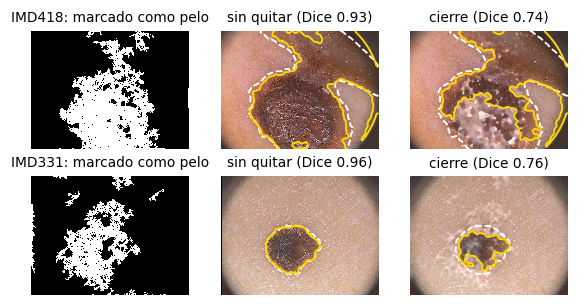

In [ ]:
# Las dos imágenes que más pierden: lo que M1 marca como pelo y la segmentación con y sin el cierre
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 3, figsize=(16 / 2.54, 8 / 2.54))
for fila, nombre in zip(ax, ["IMD418", "IMD331"]):
    caso = carga_de_datos.cargar_caso(nombre)
    sin_pelos, valida, pelos = mejoramiento.mejorar(caso.imagen, "cierre")
    graficos.mostrar(fila[0], pelos, f"{nombre}: marcado como pelo")
    for a, (titulo, img) in zip(fila[1:], (("sin quitar", caso.imagen), ("cierre", sin_pelos))):
        mascara = segmentacion.segmentar(img, valida)
        graficos.mostrar(a, img, f"{titulo} (Dice {segmentacion.dice(mascara, caso.mascara_ref):.2f})")
        graficos.contorno(a, caso.mascara_ref, referencia=True)
        graficos.contorno(a, mascara)

**Por qué pierde el cierre.** En las cuatro imágenes que más pierden, M1 marca como pelo entre el 46 % y el 78 % de la lesión: confunde la red de pigmento y la textura oscura con pelos, y el inpainting rellena esas zonas con tonos más claros, así que M3 recorta la lesión. IMD331, por ejemplo, casi no tiene pelos: lo marcado es la red y los surcos de la piel. En general, cuanta más lesión marca, más pierde (Spearman −0,47). Esto muestra además una limitación del criterio "con pelos": como lo decide el mismo detector, el grupo incluye imágenes en las que se equivoca. Tampoco es el suavizado de M3 lo que salva a no quitar los pelos, porque con σ = 1 el cierre pierde igual o más (empeora 21 de 30 imágenes contra no quitar y 24 contra la mediana).

El cierre sigue siendo el método del algoritmo porque esa decisión se tomó antes de mirar prueba y porque, a diferencia de la mediana, no suaviza la red de pigmento que mide M5. Cambiarlo ahora invalidaría la evaluación en prueba.


## 7. Resumen

| Pregunta | Resultado en prueba |
|---|---|
| ¿Se encuentra bien la lesión? | Sí, Dice medio 0,916; falla en melanomas con azul grisáceo |
| ¿A y C coinciden con el dermatólogo? | Aceptable en A (κ = 0,38) y bajo en C (κ = 0,24) |
| ¿Se detectan las estructuras de D? | Bien el velo y la regresión; peor las estrías, la red atípica y los glóbulos |
| ¿El TDS separa sospechosas de comunes? | Sí, AUC 0,77 (hipótesis 2, primera parte confirmada) |
| ¿Las zonas mejoran el TDS? | No de forma significativa, +0,02 (segunda parte no confirmada) |
| ¿Quitar los pelos mejora la segmentación? | No (hipótesis 1 no confirmada) |

Con el umbral de Youden, el TDS clasifica las 60 imágenes de prueba con una sensibilidad de 0,69 y una especificidad de 0,88.